# Segmentación de Clientes con K-Means

## Introducción y Objetivo

El presente trabajo tiene como finalidad aplicar técnicas de aprendizaje no supervisado (**Clustering con K-Means**) para identificar segmentos latentes de clientes a partir de sus comportamientos de compra y uso del sitio web. 

### Variables consideradas:
* `purchase_freq_month`: Frecuencia de compras por mes.
* `avg_basket_usd`: Ticket promedio por compra en USD.
* `time_on_site_min`: Tiempo de permanencia en el sitio (minutos).
* `discount_sensitivity`: Sensibilidad a descuentos (0 a 1).
* `returns_rate`: Tasa de devoluciones (0 a 0.8 aprox.).

## Carga de Librerías y Dataset

In [14]:
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [15]:
# Silenciar advertencias de Scikit-Learn
warnings.filterwarnings('ignore')
os.environ['OMP_NUM_THREADS'] = '1'

In [16]:
# Carga del dataset
df = pd.read_csv("../Dataset/dataset_segmentacion_clientes.csv")

In [17]:
# Selección de características pertinentes
features = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]

df[features].head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


## Preprocesamiento y Limpieza de Datos

### Verificación de Valores Faltantes

In [18]:
missing_values = df[features].isnull().sum()
print(missing_values)

if missing_values.sum() == 0:
    print('\nRESULTADO: No hay valores faltantes en el dataset.\n')
else:
    print('\nRESULTADO: Se encontraron valores faltantes.\n')

purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
dtype: int64

RESULTADO: No hay valores faltantes en el dataset.



### Detección de Outliers (Criterio de Tukey / IQR)
Evaluamos la presencia de valores atípicos en las variables numéricas utilizando el Rango Intercuartílico (IQR).

In [19]:
outliers_summary = {}

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    count = len(df[(df[col] < lower_bound) | (df[col] > upper_bound)])
    
    outliers_summary[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Outliers': count
    }

pd.DataFrame(outliers_summary)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
Q1,2.278418,90.766945,6.60395,0.0,0.0
Q3,11.214919,449.719033,34.34136,1.0,0.8
IQR,8.936501,358.952087,27.73741,1.0,0.8
Outliers,0.000000,0.000000,0.00000,0.0,0.0


> **Justificación del Escalador:**  
> Se selecciona StandardScaler porque el algoritmo K-Means se basa en distancias euclidianas, las cuales son sensibles a las diferencias de escala y dispersión entre variables. Al transformar las características para que tengan media cero y varianza unitaria ($\sigma = 1$), se garantiza que todas las variables contribuyan con el mismo peso al cálculo de los clústeres, evitando que características con mayor dispersión natural dominen el agrupamiento.

### Escalado de Variables

In [20]:
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Determinación del Número Óptimo de Clústeres ($k$)
Utilizamos el **Método del Codo (Elbow Method)** para evaluar la inercia (suma de cuadrados intra-clúster) en el rango $k \in [2, 6]$.

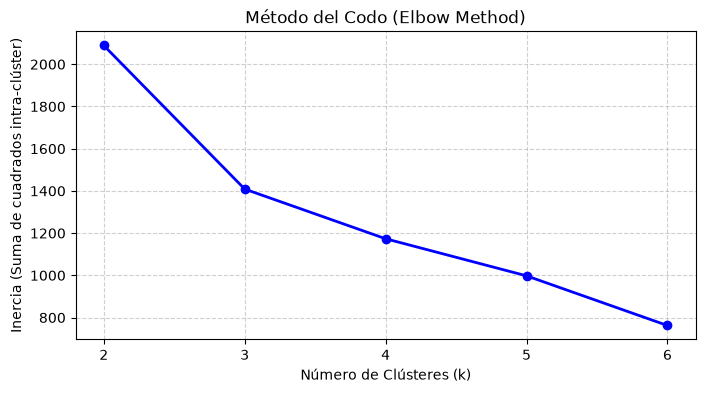

In [21]:
inertias = []
k_range = range(2, 7)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Graficar curva del codo
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, marker='o', linestyle='-', color='b', linewidth=2)
plt.title('Método del Codo (Elbow Method)')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Inercia (Suma de cuadrados intra-clúster)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

> **Interpretación del Codo:**  
> En la gráfica se observa una inflexión pronunciada en **$k = 3$**. A partir de este valor, la tasa de reducción de la inercia disminuye de forma más gradual, por lo que se selecciona **$k = 3$** como el número óptimo de clústeres.

## Determinación del Silhoutte Score

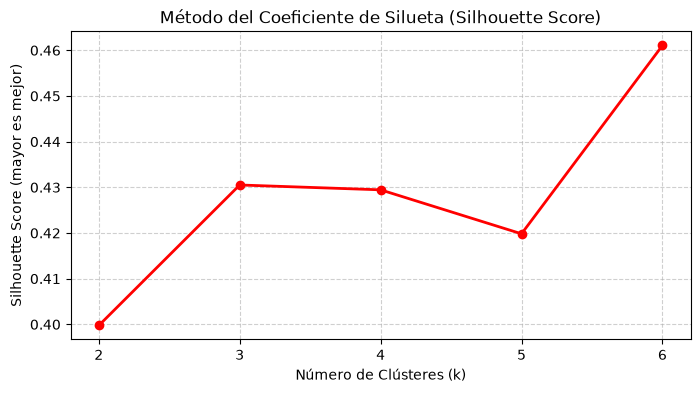

In [22]:
silhouettes = []
k_range = range(2, 7)

for k in k_range:
  kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans_temp.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, cluster_labels)
  silhouettes.append(score)

# Graficar el Coeficiente de Silueta
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouettes, marker='o', linestyle='-', color='r', linewidth=2)
plt.title('Método del Coeficiente de Silueta (Silhouette Score)')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Silhouette Score (mayor es mejor)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

> **Interpretación del Silueta:**

> Aunque el valor máximo del Coeficiente de Silueta se alcanza en $k = 6$, una división en 6 grupos sobre-fragmentaría la base de clientes con perfiles poco diferenciados comercialmente. 

> Por ello, se selecciona el segundo pico de la métrica en $k = 3$, el cual coincide de manera limpia con la inflexión identificada en el Método del Codo.La elección de $k = 3$ respalda los objetivos iniciales del proyecto al aislar con precisión los tres segmentos clave (compradores frecuentes de ticket medio, VIPs de alto valor y ocasionales), asegurando un modelo robusto, interpretable y accionable.

## Entrenamiento del Modelo K-Means ($k=3$)

In [23]:
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Asignar etiquetas de clúster al DataFrame original
df['cluster'] = clusters

## Análisis de Centroides y Visualización

### Visualización de los Clústeres

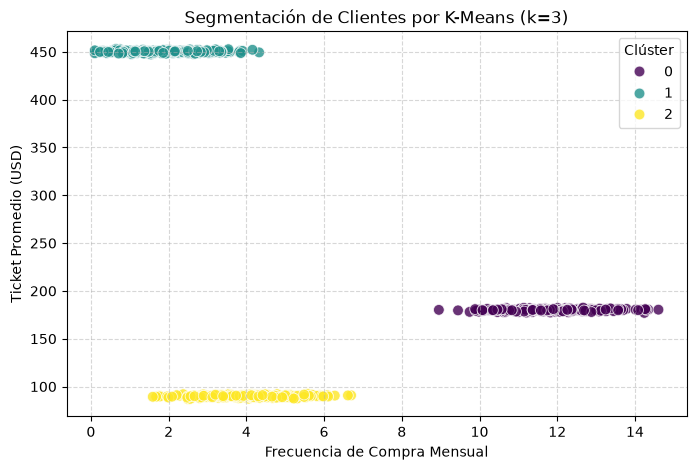

In [24]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='purchase_freq_month',
    y='avg_basket_usd',
    hue='cluster',
    palette='viridis',
    s=60,
    alpha=0.8
)
plt.title('Segmentación de Clientes por K-Means (k=3)')
plt.xlabel('Frecuencia de Compra Mensual')
plt.ylabel('Ticket Promedio (USD)')
plt.legend(title='Clúster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Perfiles de los Clústeres (Valores Reales)
Invertimos la transformación del escalador para visualizar los valores promedio de cada clúster en sus unidades originales (dólares, minutos, frecuencias, etc.).

In [25]:
centroides_escalados = kmeans.cluster_centers_
centroides_originales = scaler.inverse_transform(centroides_escalados)

df_centroides = pd.DataFrame(centroides_originales, columns=features)
df_centroides['tamano_cluster'] = [(df['cluster'] == i).sum() for i in range(k_optimo)]

df_centroides.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,tamano_cluster
0,11.96,180.00,35.02,0.54,0.33,230
1,1.85,450.12,5.97,0.36,0.38,250
2,4.09,89.96,10.00,0.38,0.30,220


## Conclusiones y Perfiles de Clientes

A partir del análisis de los centroides y la distribución gráfica, se identifican 3 segmentos latentes de clientes claramente diferenciados:

1. **Clúster 0: Clientes Frecuentes de Alto Compromiso (230 clientes)**
   * **Características:** Frecuencia de compra alta ($\approx 12$ veces/mes), ticket promedio moderado ($\approx \$180$ USD) y el mayor tiempo de navegación en el sitio ($\approx 35$ min).
   * **Estrategia comercial:** Foco en programas de fidelización, promociones cruzadas (*cross-selling*) y campañas de retención continua.

2. **Clúster 1: Compradores VIP / Esporádicos de Alto Valor (250 clientes)**
   * **Características:** Frecuencia de compra baja ($\approx 1.8$ veces/mes), pero con el ticket promedio más elevado ($\approx \$450$ USD) y baja navegación ($\approx 6$ min).
   * **Estrategia comercial:** Foco en servicio exclusivo, atención personalizada y ofertas orientadas a productos prémium (*upselling*).

3. **Clúster 2: Compradores Ocasionales de Ticket Bajo (220 clientes)**
   * **Características:** Frecuencia de compra baja/media ($\approx 4$ veces/mes), ticket promedio bajo ($\approx \$90$ USD) y tiempo de navegación acotado ($\approx 10$ min).
   * **Estrategia comercial:** Foco en cupones de descuento, combos promocionales y estrategias de activación para incentivar un mayor volumen de compra.